## SI Figures for capex and opex of each plant

In [6]:
file ='../Figures'

import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import math as math


#import csv file as a dictionary
path = '../Input_Data/BACWA_all_plants_9Apr26.csv'
LSB = pd.read_csv(path)

# function that creates dataframe from list of files in a path
def create_dataframe(path, tag):
# get all files in the path
    files = os.listdir(path)

    # create a dictionary to store all dataframes
    dfs = {}

    for file in files:
        if file.endswith('.csv'):
            # read the csv file
            df = pd.read_csv(path+file)

            if tag == 'results':
                WWTP = file.split('results_')[1]
                WWTP = WWTP.split('.csv')[0]
                if 'econ' not in WWTP:
                    dfs[WWTP] = df
            
            # if file includes tag in name
            elif 'econ' in file and tag in file:
                # create string with only the characters after "results_econ_"
                WWTP= file.split('results_econ_')[1]
                WWTP = WWTP.split('.csv')[0]
                dfs[WWTP] = df

            # if file includes flow in name
            elif 'flow' in file and tag in file:
                # create string with only the characters after "results_flow_"
                WWTP= file.split('results_flow_')[1]
                WWTP = WWTP.split('.csv')[0]
                dfs[WWTP] = df
                
    return dfs

def create_df(WWTP, dfs):
    df = dfs[WWTP]
    df.rename(columns={df.columns[0]: 'Datetime'}, inplace=True)
    df.Datetime = pd.to_datetime(df.Datetime)
    return df

In [7]:
path_case_1 = '../Results/Non_Staged/No_coordination/'
dfs_results_case_1 = create_dataframe(path_case_1, 'results')
dfs_results_flow_case_1 = create_dataframe(path_case_1, 'flow')

[Text(20209.0, 0, '2025'),
 Text(22035.0, 0, '2030'),
 Text(23861.0, 0, '2035'),
 Text(25688.0, 0, '2040'),
 Text(27514.0, 0, '2045'),
 Text(29340.0, 0, '2050'),
 Text(31136.0, 0, '2055')]

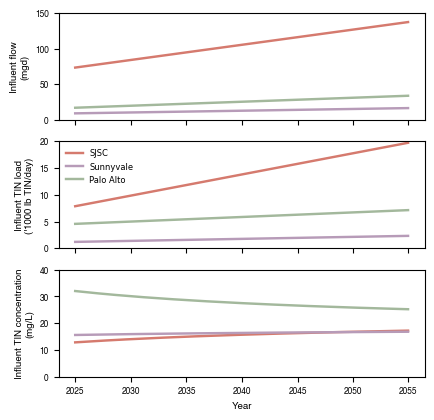

In [8]:
colors_WWTP = {'SJSC': '#D57A6E', 'Sunnyvale': '#B79BB8', 'Palo Alto': '#A3B89C'}
colors_L = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'L2upg3': '#EB5E28'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2

lab = ['(a)', '(b)', '(c)']

#def plot_projected_flow(WWTP, i, dfs_result_flow):
WWTP = 'Palo Alto'
WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']
fig, ax = plt.subplots(3,1, figsize=(120/25.4, 120/25.4))

for WWTP in WWTPs:
    dfs_results_flow = dfs_results_flow_case_1
    df = create_df(WWTP, dfs_results_flow)
    years = [df.Datetime[t] for t in range(0, len(df.Datetime), 5*12)] + [pd.to_datetime('2055-04-01')]

    ax[0].plot(df.Datetime, df['Influent_flow'], color=colors_WWTP[WWTP], linewidth=line_wid+1)
    ax[1].plot(df.Datetime, df['Influent_load']*0.001, color=colors_WWTP[WWTP], linewidth=line_wid+1)
    ax[2].plot(df.Datetime, df['Influent_conc'], color=colors_WWTP[WWTP], linewidth=line_wid+1)



# Plot influent flow
ax[0].set_ylim(0,150)
ax[0].set_ylabel('Influent flow\n(mgd)', **hfont)
ax[0].set_yticks([0, 50, 100, 150])
ax[0].set_yticklabels(['0', '50', '100', '150'], **hfont_ticks)
ax[0].set_xticks(years)
ax[0].set_xticklabels([], **hfont_ticks)


# Plot projected mass flow
ax[1].set_ylim(0, 20)
ax[1].set_ylabel("Influent TIN load\n('1000 lb TIN/day)", **hfont)
ax[1].set_yticks([0, 5, 10, 15, 20])
ax[1].set_yticklabels(['0', '5', '10', '15', '20'], **hfont_ticks)
ax[1].set_xticks(years)
ax[1].set_xticklabels([], **hfont_ticks)
ax[1].legend(WWTPs, fontsize=leg_size, frameon=False, loc='upper left')

# plot projected TIN concentration
ax[2].set_ylim(0, 40)
ax[2].set_yticks([0, 10, 20, 30, 40])
ax[2].set_yticklabels(['0', '10', '20', '30', '40'], **hfont_ticks)
ax[2].set_ylabel('Influent TIN concentration\n(mg/L)', **hfont)
ax[2].set_xlabel('Year', **hfont)
ax[2].set_xticks(years)
ax[2].set_xticklabels([year.strftime('%Y') for year in years], **hfont_ticks)

index of final year: 352
Annual growth rate load: 3.01%, Annual growth rate flow: 2.04%
Monthly growth rate load: 0.26%, Monthly growth rate flow: 0.17%
index of final year: 352
Annual growth rate load: 2.15%, Annual growth rate flow: 1.91%
Monthly growth rate load: 0.18%, Monthly growth rate flow: 0.16%
index of final year: 352
Annual growth rate load: 1.45%, Annual growth rate flow: 2.23%
Monthly growth rate load: 0.12%, Monthly growth rate flow: 0.19%


[Text(20209.0, 0, '2025'),
 Text(22035.0, 0, '2030'),
 Text(23861.0, 0, '2035'),
 Text(25688.0, 0, '2040'),
 Text(27514.0, 0, '2045'),
 Text(29340.0, 0, '2050'),
 Text(31136.0, 0, '2055')]

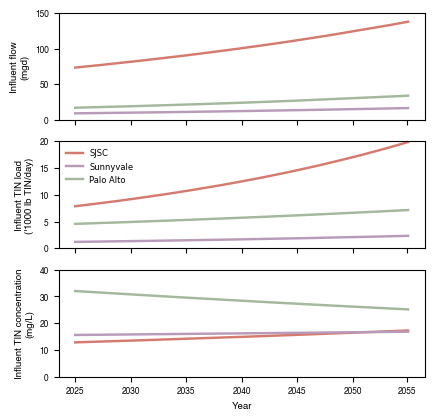

In [18]:
from matplotlib import colors


colors_WWTP = {'SJSC': '#D57A6E', 'Sunnyvale': '#B79BB8', 'Palo Alto': '#A3B89C'}
colors_L = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'L2upg3': '#EB5E28'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2

lab = ['(a)', '(b)', '(c)']
eq_tag = 'exponential'

#def plot_projected_flow(WWTP, i, dfs_result_flow):
WWTP = 'Palo Alto'
WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']
fig, ax = plt.subplots(3,1, figsize=(120/25.4, 120/25.4))

for WWTP in WWTPs:
    #create a monthly time series from 2025 to 2055 with datetime format
    df_w = LSB[LSB['Abbreviation'] == WWTP]
    monthly_dates = pd.date_range(start='2025-05-01', end='2055-05-01', freq='MS')
    months = np.arange(0, len(monthly_dates))
    years_plot = [df.Datetime[t] for t in range(0, len(df.Datetime), 5*12)] + [pd.to_datetime('2055-04-01')]
    years = np.arange(monthly_dates[0].year, monthly_dates[-1].year+1, 1)
    lbNpermgd_to_mgNperL = 0.119804668
    
    load_current = df_w.Average_TIN_Dry_ECHO_current.item()* 2.204623 # convert from kg N/day to lb N/day
    load_projected = df_w["Average_TIN_Dry_BACWA_projected (lb N/day)"].item()
    flow_current = df_w.Average_Flow_Dry_ECHO_current.item()
    flow_projected = df_w.Average_Flow_Dry_BACWA_projected.item()

    if eq_tag == 'linear':
        # fit linear series to load and flow data
        z = np.polyfit([months[0], months[-1]], [load_current, load_projected], 1)
        m, b = z[0], z[1]
        z_flow = np.polyfit([months[0], months[-1]], [flow_current, flow_projected], 1)
        m_flow, b_flow = z_flow[0], z_flow[1]
        load_series = m * months + b
        flow_series = m_flow * months + b_flow
        conc_series = (load_series)/flow_series * lbNpermgd_to_mgNperL 

    if eq_tag == 'exponential':
        growth_rate_load_annual = (load_projected / load_current)**(1/len(years)) - 1
        growth_rate_flow_annual = (flow_projected / flow_current)**(1/len(years)) - 1
        # calculate the last point
        projected_linear_load = np.linspace(load_current, load_projected, len(months))
        projected_linear_flow = np.linspace(flow_current, flow_projected, len(months))
        ind_final_year = np.where(monthly_dates == pd.to_datetime('2054-09-01'))[0][0]
        load_final_year = projected_linear_load[ind_final_year]
        flow_final_year = projected_linear_flow[ind_final_year]
        print(f'index of final year: {ind_final_year}')

        growth_rate_load = (load_final_year / load_current)**(1/len(months[:ind_final_year])) - 1
        growth_rate_flow = (flow_final_year / flow_current)**(1/len(months[:ind_final_year])) - 1

        print(f'Annual growth rate load: {growth_rate_load_annual*100:.2f}%, Annual growth rate flow: {growth_rate_flow_annual*100:.2f}%')
        print(f'Monthly growth rate load: {growth_rate_load*100:.2f}%, Monthly growth rate flow: {growth_rate_flow*100:.2f}%')
        
        load_series = load_current * (1 + growth_rate_load)**(months)
        flow_series = flow_current * (1 + growth_rate_flow)**(months)
        conc_series = (load_series)/flow_series * lbNpermgd_to_mgNperL
        #ax[0].plot(monthly_dates, projected_linear_flow, color=colors_WWTP[WWTP], linewidth=line_wid, linestyle='--', label='')
        #ax[1].plot(monthly_dates, projected_linear_load/1000, color=colors_WWTP[WWTP], linewidth=line_wid, linestyle='--', label='')
        
        #print(f'Load projected in years 2054-09-1: {projected_linear_load[ind_final_year]:.2f} lb N/day, Flow projected in years 2054-09-1: {projected_linear_flow[ind_final_year]:.2f} mgd')
        #print(f'Load projected in years 2054-09-1: {load_series[ind_final_year]:.2f} lb N/day, Flow projected in years 2054-09-1: {flow_series[ind_final_year]:.2f} mgd')
    
    ax[0].plot(monthly_dates, flow_series, color=colors_WWTP[WWTP], linewidth=line_wid+1)
    ax[1].plot(monthly_dates, load_series/1000, color=colors_WWTP[WWTP], linewidth=line_wid+1, label = WWTP)
    ax[2].plot(monthly_dates, conc_series, color=colors_WWTP[WWTP], linewidth=line_wid+1)



# Plot influent flow
ax[0].set_ylim(0,150)
ax[0].set_ylabel('Influent flow\n(mgd)', **hfont)
ax[0].set_yticks([0, 50, 100, 150])
ax[0].set_yticklabels(['0', '50', '100', '150'], **hfont_ticks)
ax[0].set_xticks(years_plot)
ax[0].set_xticklabels([], **hfont_ticks)


# Plot projected mass flow
ax[1].set_ylim(0, 20)
ax[1].set_ylabel("Influent TIN load\n('1000 lb TIN/day)", **hfont)
ax[1].set_yticks([0, 5, 10, 15, 20])
ax[1].set_yticklabels(['0', '5', '10', '15', '20'], **hfont_ticks)
ax[1].set_xticks(years_plot)
ax[1].set_xticklabels([], **hfont_ticks)
ax[1].legend(fontsize=leg_size, frameon=False, loc='upper left')

# plot projected TIN concentration
ax[2].set_ylim(0, 40)
ax[2].set_yticks([0, 10, 20, 30, 40])
ax[2].set_yticklabels(['0', '10', '20', '30', '40'], **hfont_ticks)
ax[2].set_ylabel('Influent TIN concentration\n(mg/L)', **hfont)
ax[2].set_xlabel('Year', **hfont)
ax[2].set_xticks(years_plot)
ax[2].set_xticklabels([year.strftime('%Y') for year in years_plot], **hfont_ticks)

In [ ]:
colors = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'L2upg3': '#EB5E28'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2

tags = ['BACWA_Current_conc',	'Average_TIN_Dry_BACWA_projected (lb N/day)',	'Average_Flow_Dry_BACWA_current',	'Average_Flow_Dry_BACWA_projected',
        'Opex_min_L2',	'Opex_max_L2',	'Opex_avg_dry_L2',	'Opex_avg_year_L2',	'Opex_dry_mil_L2',	'Opex_year_mil_L2',
        'Opex_min_L3',	'Opex_max_L3',	'Opex_avg_dry_L3',	'Opex_avg_year_L3',	'Opex_dry_mil_L3',	'Opex_year_mil_L3']

lab = ['(a)', '(b)', '(c)']

def plot_opex_WWTP(WWTP, i):
        df = LSB[LSB['Abbreviation'] == WWTP]
        # L2 tags
        opex_min_L2 = df[tags[4]]
        opex_max_L2 = df[tags[5]]
        opex_avg_L2 = [df[tags[6]], df[tags[7]]]
        opex_mil_L2 = [df[tags[8]], df[tags[9]]]

        # L3 tags
        opex_min_L3 = df[tags[10]]
        opex_max_L3 = df[tags[11]]
        opex_avg_L3 = [df[tags[12]], df[tags[13]]]
        opex_mil_L3 = [df[tags[14]], df[tags[15]]]

        # create figure
        fig, ax = plt.subplots(1,1, figsize=(120/25.4, 70/25.4))

        # plot data points
        plt.scatter(opex_avg_L2, opex_mil_L2, color='black', label='L2 average opex', marker='o', s=25)
        plt.scatter(opex_avg_L3, opex_mil_L3, color='red', label='L3 average opex', marker='x', s=25)

        # find best fit linear line 
        # create new list that contains both opex_avg_L2 and opex_avg_L3
        opex_avg = []
        opex_mil = []
        opex_bound = []
        
        for j in range(2):
                opex_avg.append(opex_avg_L2[j].item())
                opex_mil.append(opex_mil_L2[j].item())
        for j in range(2):
                opex_avg.append(opex_avg_L3[j].item())
                opex_mil.append(opex_mil_L3[j].item())
        opex_bound.append(opex_min_L2.iloc[0])
        opex_bound.append(opex_max_L3.iloc[0])
                
        
        z = np.polyfit(opex_avg, opex_mil, 1)
        p = np.poly1d(z)
        plt.plot(opex_bound, p(opex_bound), color='black', linestyle='--', linewidth=1, label='Line of best fit')
        
        #calculate R2
        r2 = np.corrcoef(opex_mil, p(opex_avg))[0, 1]**2

        #calculate RMSE
        rmse = np.sqrt(np.mean((p(opex_avg) - opex_mil)**2))*100
        
        
        # plot vertical line at opex_min and opex_max
        # plot vertical line at opex_min and opex_max
        plt.vlines(opex_min_L2, ymin=0, ymax= p(opex_min_L2.iloc[0]), color='black', linestyle='dashdot', label='bounds of L2 operation', linewidth= line_wid)
        plt.vlines(opex_max_L2, ymin=0, ymax= p(opex_max_L2.iloc[0]), color='black', linestyle='dashdot',linewidth= line_wid)

        plt.vlines(opex_min_L3, ymin=0, ymax=p(opex_min_L3.iloc[0]), color='red', linestyle='dashdot', label='bounds of L3 operation',linewidth= line_wid)
        plt.vlines(opex_max_L3, ymin=0, ymax=p(opex_max_L3.iloc[0]), color='red', linestyle='dashdot', linewidth= line_wid)

        ax.set_xlabel('TIN removed \n(lb N/day)', **hfont)
        ax.set_ylabel('Opex \n(mil $/year)', **hfont)
        ax.set_title(lab[i] + ' ' + WWTP, **hfont)
        min_x = math.floor(opex_min_L2.iloc[0]/ 2000) * 2000
        max_x = math.ceil(opex_max_L3.iloc[0] / 2000) * 2000
        ax.set_xlim(min_x, max_x)
        
        min_y = math.ceil(opex_mil_L3[1].item()/5)*5
        ax.set_ylim(0, min_y)
        ax.set_yticks(np.arange(0, min_y+1, 2.5))
        

        x_scale = [1, 0.2, 0.2]
        y_scale = [0.2, 0.7, 0.7]

        # add equation for best fit line
        text1 = 'y = ' + str(round(z[0], 4)) + 'x + ' + str(round(z[1], 3))
        text2 = '$R^{2}$=%.3f'%r2
        text3 = 'RMSE=%.1f'%rmse + '%'
        plt.text((min_x + max_x)/2 * x_scale[i], min_y * y_scale[i], text1 + '\n' + text2 + '\n' + text3, fontsize=leg_size, color='black', fontfamily='Helvetica')
        

        
        ax.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
        ax.tick_params(axis="both", width=line_wid, length=bord_wid)

        if i == 0:
                ax.legend(loc='upper left', fontsize=10, frameon=False, bbox_to_anchor=(0.05, 0.95), prop={'family':'Helvetica', 'size':leg_size}, ncol = 2)
        fig.tight_layout()

        fig.savefig(file + '/SI' + name + lab[i][1] + '_' + WWTP + ".svg", format="svg", dpi=300)


/home/sinan/miniconda3/envs/sfbaycap/lib/python3.11/site-packages/matplotlib/cbook.py:1762: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


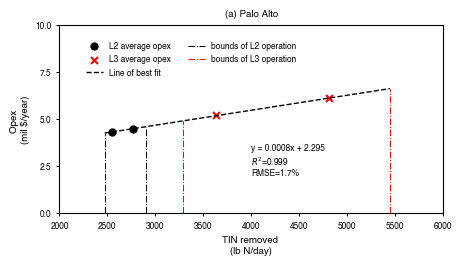

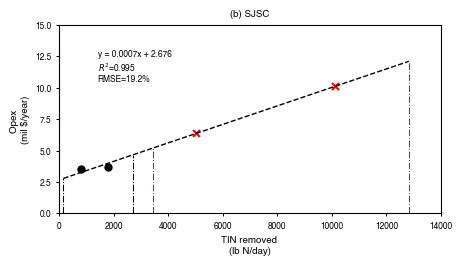

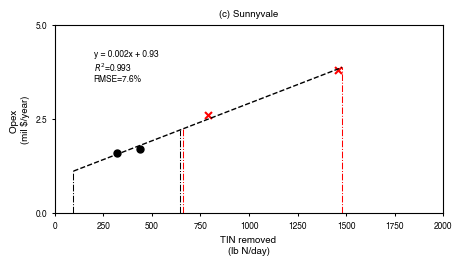

In [ ]:
name = '/S9'

for i,WWTP in enumerate(LSB['Abbreviation']):
    plot_opex_WWTP(WWTP, i)

## Plot capital costs of upgrades in each WWTP

In [ ]:
tags = ['BACWA_Current_conc',	'Average_TIN_Dry_BACWA_projected (lb N/day)',	'Average_Flow_Dry_BACWA_current',	'Average_Flow_Dry_BACWA_projected',
        'Opex_min_L2',	'Opex_max_L2',	'Opex_avg_dry_L2',	'Opex_avg_year_L2',	'Opex_dry_mil_L2',	'Opex_year_mil_L2',
        'Opex_min_L3',	'Opex_max_L3',	'Opex_avg_dry_L3',	'Opex_avg_year_L3',	'Opex_dry_mil_L3',	'Opex_year_mil_L3',
        'Capex_L2_LB_max',	'Capex_L2_UB_max',	'Capex_dry_mil_L2',	'Capex_year_mil_L2',
        'Capex_L3_LB_max',	'Capex_L3_UB_max',	'Capex_dry_mil_L3',	'Capex_year_mil_L3']


def get_flat(df, *tag_indices):
    return pd.concat([df[tags[i]] for i in tag_indices]).dropna().values

def fit_linear(X, C):
    """Fit C = m * X + b. """
    z = np.polyfit(X, C, 1)
    m, b = z[0], z[1]
    return m, b

def fit_power_law(X, C):
    """Fit C = a * X^b. """
    if len(X) == 2:
        b = np.log(C[1] / C[0]) / np.log(X[1] / X[0])
        a = C[0] / X[0]**b
    else:
        z = np.polyfit(np.log(X), np.log(C), 1)
        b, a = z[0], np.exp(z[1])
    return a, b

def sig_figs(x, sig=3):
    """Return a formatted string of x to a given number of significant figures."""
    if x == 0:
        return '0'
    digits = sig - int(np.floor(np.log10(abs(x)))) - 1
    if abs(x) > 0.001:
        return f'{x:.{max(0, digits)}f}'
    else:
        # return scientific notation with sig significant figures
        return f'{x:.{sig-1}e}'

def capex_WWTP_vs_TIN(WWTP, eq_type= 'linear'):
    df = LSB[LSB['Abbreviation'] == WWTP]
    
    # L2 tags
    capex_design_L2 = get_flat(df, 16, 17)
    capex_mil_L2 = get_flat(df, 18, 19)

    # L3 tags
    capex_design_L3 = get_flat(df, 20, 21)
    capex_mil_L3 = get_flat(df, 22, 23)
    
    print(f'WWTP: {WWTP}')
    print(f'        Design capacity for L2 between: {round(capex_design_L2[0].item())} lb/day and {round(capex_design_L2[1].item())} lb/day')
    print(f'        Design capacity for L3 between: {round(capex_design_L3[0].item())} lb/day and {round(capex_design_L3[1].item())} lb/day')

    if eq_type == 'linear':
        m2, b2 = fit_linear(capex_design_L2, capex_mil_L2)
        m3, b3 = fit_linear(capex_design_L3, capex_mil_L3)
        return m2, b2, m3, b3, capex_design_L2, capex_design_L3, capex_mil_L2, capex_mil_L3

    elif eq_type == 'power':
        a2, b2 = fit_power_law(capex_design_L2, capex_mil_L2)
        a3, b3 = fit_power_law(capex_design_L3, capex_mil_L3) 
        return a2, b2, a3, b3, capex_design_L2, capex_design_L3, capex_mil_L2, capex_mil_L3

    else:
        raise ValueError("eq_type must be either 'linear' or 'power'")

def calculate_capex_WWTP_vs_flow(WWTP, eq_type= 'linear'):
    lbNpermgd_to_mgNperL = 0.119804668
    df_w = LSB[LSB['Abbreviation'] == WWTP]

    if eq_type == 'linear':
            m2, b2, m3, b3, capex_design_L2, capex_design_L3, capex_mil_L2, capex_mil_L3 = capex_WWTP_vs_TIN(WWTP, eq_type='linear')
            TIN_load_L2 = np.linspace(capex_design_L2[0], capex_design_L2[1], 100)
            flow_L2 = TIN_load_L2 / (df_w.L2_design_conc.item()- 15) * lbNpermgd_to_mgNperL
            TIN_load_L3 = np.linspace(capex_design_L3[0], capex_design_L3[1], 100)
            flow_L3 = TIN_load_L3 / (df_w.L2_design_conc.item() - 6) * lbNpermgd_to_mgNperL
            capex_L2 = m2* TIN_load_L2 + b2 
            capex_L3 = m3* TIN_load_L3 + b3

    if eq_type == 'power':
        a2, b2, a3, b3, capex_design_L2, capex_design_L3, capex_mil_L2, capex_mil_L3 = capex_WWTP_vs_TIN(WWTP, eq_type='power')
        TIN_load_L2 = np.linspace(capex_design_L2[0], capex_design_L2[1], 100)
        TIN_load_L3 = np.linspace(capex_design_L3[0], capex_design_L3[1], 100)
        flow_L2 = TIN_load_L2 / (df_w.L2_design_conc.item() - 15) * lbNpermgd_to_mgNperL
        flow_L3 = TIN_load_L3 / (df_w.L2_design_conc.item() - 6) * lbNpermgd_to_mgNperL

        capex_L2 = a2 * TIN_load_L2**b2
        capex_L3 = a3 * TIN_load_L3**b3
    
    return flow_L2, capex_L2, flow_L3, capex_L3, capex_mil_L2, capex_mil_L3, capex_design_L2, capex_design_L3, TIN_load_L2, TIN_load_L3


def plot_capex_WWTP(WWTP, i, eq_type= 'linear'):
        df = LSB[LSB['Abbreviation'] == WWTP]
        # L2 tags
        capex_design_L2 = get_flat(df, 16, 17)
        capex_mil_L2 = get_flat(df, 18, 19)

        # L3 tags
        capex_design_L3 = get_flat(df, 20, 21)
        capex_mil_L3 = get_flat(df, 22, 23)

        # create figure
        fig, ax = plt.subplots(1,1, figsize=(80/25.4, 60/25.4))

        # plot data points
        plt.scatter(capex_design_L2, capex_mil_L2, color='black', label='L2 capex', marker='o', s=15)
        plt.scatter(capex_design_L3, capex_mil_L3, color='red', label='L3 capex', marker='x', s=15)
        print(f'WWTP: {WWTP}')
        print(f'        Design capacity for L2 between: {round(capex_design_L2[0].item())} lb/day and {round(capex_design_L2[1].item())} lb/day')
        print(f'        Design capacity for L3 between: {round(capex_design_L3[0].item())} lb/day and {round(capex_design_L3[1].item())} lb/day')

        if eq_type == 'linear':
            m2, b2 = fit_linear(capex_design_L2, capex_mil_L2)
            m3, b3 = fit_linear(capex_design_L3, capex_mil_L3)
            
            plt.plot(capex_design_L2, capex_mil_L2, color='black', linestyle='-', linewidth=line_wid)
            plt.plot(capex_design_L3, capex_mil_L3, color='red', linestyle='-', linewidth=line_wid)

            L2_str = f'L2: C = {sig_figs(m2)} * X + {sig_figs(b2)}'
            L3_str = f'L3: C = {sig_figs(m3)} * X + {sig_figs(b3)}'
            ax.text(0.5, 0.4, f'{L2_str}\n{L3_str}', transform=ax.transAxes, fontsize=leg_size, verticalalignment='top', horizontalalignment='left', fontfamily='Helvetica')

        
        elif eq_type == 'power':
            a2, b2 = fit_power_law(capex_design_L2, capex_mil_L2)
            a3, b3 = fit_power_law(capex_design_L3, capex_mil_L3)

            print(f'Power law L2: C = {sig_figs(a2)} * X^{sig_figs(b2)}')
            print(f'Power law L3: C = {sig_figs(a3)} * X^{sig_figs(b3)}')

            L2_str = f'$\\mathrm{{L2: C = {sig_figs(a2)} \ X^{{\\mathrm{{{sig_figs(b2)}}}}}}}$'
            L3_str = f'$\\mathrm{{L3: C = {sig_figs(a3)} \ X^{{\\mathrm{{{sig_figs(b3)}}}}}}}$'
            ax.text(0.6, 0.4, f'{L2_str}\n{L3_str}',
                    transform=ax.transAxes, fontsize=leg_size, 
                    verticalalignment='top', horizontalalignment='left', 
                    fontfamily='Helvetica')

            X2_range = np.linspace(min(capex_design_L2), max(capex_design_L2), 200)
            X3_range = np.linspace(min(capex_design_L3), max(capex_design_L3), 200)

            plt.plot(X2_range, a2 * X2_range**b2, color='black', linestyle='-', linewidth=line_wid)
            plt.plot(X3_range, a3 * X3_range**b3, color='red',   linestyle='-', linewidth=line_wid)
                

        ax.set_xlabel('Design capacity for TIN removal \n(lb N/day)', **hfont)
        ax.set_ylabel('Capex \n(mil $)', **hfont)
        ax.set_title(lab[i] + ' ' + WWTP, **hfont)
        min_x = math.floor(capex_design_L2[0].item()/ 2000) * 2000
        max_x = math.ceil(capex_design_L3[1].item() / 2000) * 2000
        ax.set_xlim(min_x, max_x)
        
        max_y = math.ceil(capex_mil_L3[1].item()/100)*100
        ax.set_ylim(0, max_y)
        ytck = [50, 150, 100]
        ax.set_yticks(np.arange(0, max_y+1, ytck[i]))

        
        ax.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
        ax.tick_params(axis="both", width=line_wid, length=bord_wid)

        if i == 0:
            ax.legend(loc='lower left', fontsize=10, frameon=False, prop={'family':'Helvetica', 'size':leg_size})
        fig.tight_layout()

        fig.savefig(file + '/SI' + name + lab[i][1] + '_' + WWTP + ".svg", format="svg", dpi=300)
    

def plot_capex_WWTP_flow(WWTP, i, eq_type= 'linear'):
        lbNpermgd_to_mgNperL = 0.119804668
        df_w = LSB[LSB['Abbreviation'] == WWTP]
        
        flow_design_L2 = np.array([df_w.L2_flow_LB_max.item(), df_w.L2_flow_UB_max.item()])
        flow_design_L3 = np.array([df_w.L3_flow_LB_max.item(), df_w.L3_flow_UB_max.item()])
        
        flow_L2, capex_L2, flow_L3, capex_L3, capex_mil_L2, capex_mil_L3 = calculate_capex_WWTP_vs_flow(WWTP, eq_type=eq_type)
        
        # create figure
        fig, ax = plt.subplots(1,1, figsize=(80/25.4, 60/25.4))
        
        plt.scatter(flow_design_L2, capex_mil_L2, color='black', label='L2 capex', marker='o', s=15)
        plt.scatter(flow_design_L3, capex_mil_L3, color='red', label='L3 capex', marker='x', s=15)
        
        ax.plot(flow_L2, capex_L2, color='black', linestyle='-', linewidth=line_wid, label='')
        ax.plot(flow_L3, capex_L3, color='red',   linestyle='-', linewidth=line_wid, label='')

        ax.set_xlabel('Design capacity for flow \n(mgd)', **hfont)
        ax.set_ylabel('Capex \n(mil $)', **hfont)
        ax.set_title(lab[i] + ' ' + WWTP, **hfont)
        
        xtick = [10, 25, 5]
        min_x = math.floor(min(min(flow_L2), min(flow_L3))/ xtick[i]) * xtick[i]
        max_x = math.ceil(max(max(flow_L2), max(flow_L3))/ xtick[i]) * xtick[i]
        ax.set_xlim(min_x, max_x)
        
        max_y = math.ceil(max(max(capex_L2), max(capex_L3))/100)*100
        ax.set_ylim(0, max_y)
        ytck = [50, 150, 100]
        ax.set_yticks(np.arange(0, max_y+1, ytck[i]))

        
        ax.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
        ax.tick_params(axis="both", width=line_wid, length=bord_wid)

        if i == 0:
            ax.legend(loc='lower left', fontsize=10, frameon=False, prop={'family':'Helvetica', 'size':leg_size})
        fig.tight_layout()
        
        return

def plot_capex_WWTP_flow_both(WWTP, i, eq_type= 'linear'):
        lbNpermgd_to_mgNperL = 0.119804668
        df_w = LSB[LSB['Abbreviation'] == WWTP]
        
        flow_design_L2 = np.array([df_w.L2_flow_LB_max.item(), df_w.L2_flow_UB_max.item()])
        flow_design_L3 = np.array([df_w.L3_flow_LB_max.item(), df_w.L3_flow_UB_max.item()])
        
        flow_L2, capex_L2, flow_L3, capex_L3, capex_mil_L2, capex_mil_L3, capex_design_L2, capex_design_L3, TIN_load_L2, TIN_load_L3 = calculate_capex_WWTP_vs_flow(WWTP, eq_type=eq_type)
        
        # create figure
        fig, ax = plt.subplots(1,2, figsize=(140/25.4, 60/25.4))
        
        ax[0].scatter(capex_design_L2, capex_mil_L2, color='black', label='L2 capex', marker='o', s=15)
        ax[0].scatter(capex_design_L3, capex_mil_L3, color='red', label='L3 capex', marker='x', s=15)
        ax[0].plot(TIN_load_L2, capex_L2, color='black', linestyle='-', linewidth=line_wid, label='')
        ax[0].plot(TIN_load_L3, capex_L3, color='red',   linestyle='-', linewidth=line_wid, label='')
        
        ax[1].scatter(flow_design_L2, capex_mil_L2, color='black', label='L2 capex', marker='o', s=15)
        ax[1].scatter(flow_design_L3, capex_mil_L3, color='red', label='L3 capex', marker='x', s=15)
        ax[1].plot(flow_L2, capex_L2, color='black', linestyle='-', linewidth=line_wid, label='')
        ax[1].plot(flow_L3, capex_L3, color='red',   linestyle='-', linewidth=line_wid, label='')

        ax[0].set_xlabel('Design capacity for TIN removal \n(lb N/day)', **hfont)
        ax[1].set_xlabel('Design capacity for flow \n(mgd)', **hfont)
        ax[0].set_ylabel('Capex (mil $)', **hfont)

        min_x = math.floor(capex_design_L2[0].item()/ 2000) * 2000
        max_x = math.ceil(capex_design_L3[1].item() / 2000) * 2000
        ax[0].set_xlim(min_x, max_x)
        
        xtick = [10, 25, 5]
        xtick_minor = [5, 25, 2.5]
        min_x = math.floor(min(min(flow_L2), min(flow_L3))/ xtick[i]) * xtick[i]
        max_x = math.ceil(max(max(flow_L2), max(flow_L3))/ xtick[i]) * xtick[i]
        ax[1].set_xlim(min_x, max_x)
        ax[1].set_xticks(np.arange(min_x, max_x+1, xtick_minor[i]))
        
        
        max_y = math.ceil(max(max(capex_L2), max(capex_L3))/100)*100
        ytck = [50, 150, 100]
        for j in range(2):
            ax[j].set_ylim(0, max_y)
            ax[j].set_yticks(np.arange(0, max_y+1, ytck[i]))
        ax[1].set_yticklabels([])

        
        ax[0].tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
        ax[1].tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')

        # add text of equations
        if eq_type == 'linear':
            m2, b2 = fit_linear(capex_design_L2, capex_mil_L2)
            m3, b3 = fit_linear(capex_design_L3, capex_mil_L3)            
            
            sign_b2 = '+' if b2 >= 0 else '-'
            sign_b3 = '+' if b3 >= 0 else '-'

            L2_str = f'L2: C = {sig_figs(m2)} * X {sign_b2} {sig_figs(abs(b2))}'
            L3_str = f'L3: C = {sig_figs(m3)} * X {sign_b3} {sig_figs(abs(b3))}'

            L2_str_flow = f'L2: C = {sig_figs(m2/(df_w.L2_design_conc.item() - 15) * lbNpermgd_to_mgNperL)} * Q {sign_b2} {sig_figs(abs(b2))}'
            L3_str_flow = f'L3: C = {sig_figs(m3/(df_w.L3_design_conc.item() - 15) * lbNpermgd_to_mgNperL)} * Q {sign_b3} {sig_figs(abs(b3))}'

        
        elif eq_type == 'power':
            a2, b2 = fit_power_law(capex_design_L2, capex_mil_L2)
            a3, b3 = fit_power_law(capex_design_L3, capex_mil_L3)

            L2_str = f'$\\mathrm{{L2: C = {sig_figs(a2)} \ X^{{\\mathrm{{{sig_figs(b2)}}}}}}}$'
            L3_str = f'$\\mathrm{{L3: C = {sig_figs(a3)} \ X^{{\\mathrm{{{sig_figs(b3)}}}}}}}$'
            L2_str_flow = f'$\\mathrm{{L2: C = {sig_figs(a2 * (1/(df_w.L2_design_conc.item() - 15) * lbNpermgd_to_mgNperL)**b2)} \ Q^{{\\mathrm{{{sig_figs(b2)}}}}}}}$'
            L3_str_flow = f'$\\mathrm{{L3: C = {sig_figs(a3 * (1/(df_w.L3_design_conc.item() - 15) * lbNpermgd_to_mgNperL)**b3)} \ Q^{{\\mathrm{{{sig_figs(b3)}}}}}}}$'

        ax[0].text(0.5, 0.05, f'{L2_str}\n{L3_str}', transform=ax[0].transAxes, fontsize=leg_size, verticalalignment='bottom', horizontalalignment='left', fontfamily='Helvetica')
        ax[1].text(0.5, 0.05, f'{L2_str_flow}\n{L3_str_flow}', transform=ax[1].transAxes, fontsize=leg_size, verticalalignment='bottom', horizontalalignment='left', fontfamily='Helvetica')
        
        if i == 0:
            ax[0].legend(loc='lower left', fontsize=10, frameon=False, prop={'family':'Helvetica', 'size':leg_size})
        fig.tight_layout()
        
        return
        
        
        

WWTP: Palo Alto
        Design capacity for L2 between: 2628 lb/day and 2902 lb/day
        Design capacity for L3 between: 3974 lb/day and 5445 lb/day
WWTP: Palo Alto
        Design capacity for L2 between: 2628 lb/day and 2902 lb/day
        Design capacity for L3 between: 3974 lb/day and 5445 lb/day
WWTP: SJSC
        Design capacity for L2 between: 1453 lb/day and 2717 lb/day
        Design capacity for L3 between: 6575 lb/day and 12822 lb/day
WWTP: SJSC
        Design capacity for L2 between: 1453 lb/day and 2717 lb/day
        Design capacity for L3 between: 6575 lb/day and 12822 lb/day
WWTP: Sunnyvale
        Design capacity for L2 between: 544 lb/day and 645 lb/day
        Design capacity for L3 between: 918 lb/day and 1480 lb/day
WWTP: Sunnyvale
        Design capacity for L2 between: 544 lb/day and 645 lb/day
        Design capacity for L3 between: 918 lb/day and 1480 lb/day


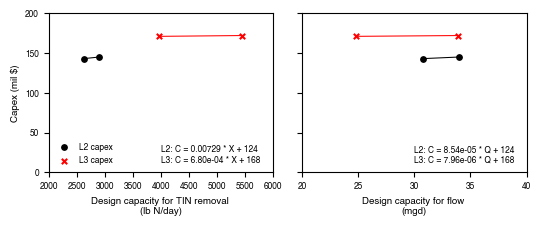

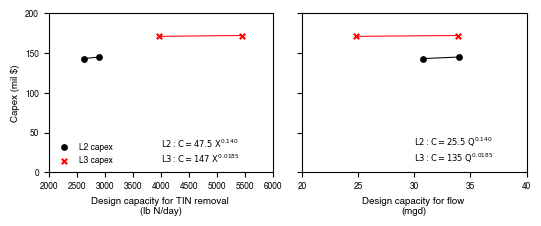

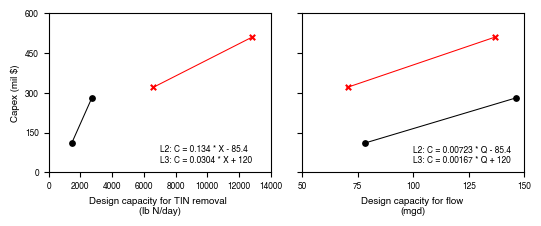

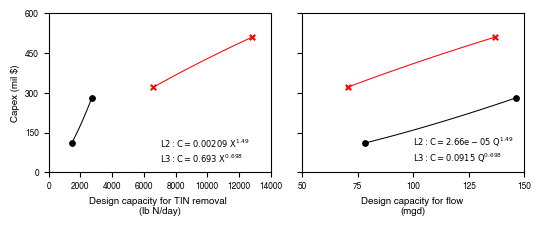

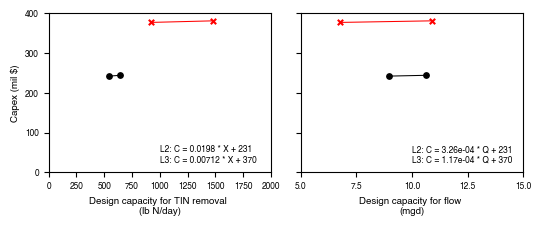

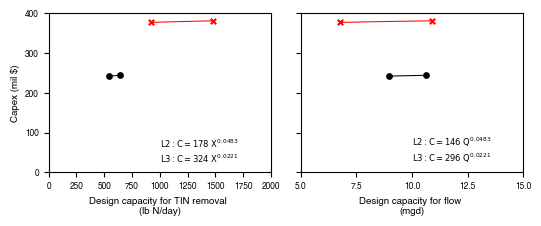

In [ ]:
for i,WWTP in enumerate(LSB['Abbreviation']):
    plot_capex_WWTP_flow_both(WWTP, i, eq_type='linear')
    plot_capex_WWTP_flow_both(WWTP, i, eq_type='power')

WWTP: Palo Alto
        Design capacity for L2 between: 2628 lb/day and 2902 lb/day
        Design capacity for L3 between: 3974 lb/day and 5445 lb/day
WWTP: Palo Alto
        Design capacity for L2 between: 2628 lb/day and 2902 lb/day
        Design capacity for L3 between: 3974 lb/day and 5445 lb/day
WWTP: SJSC
        Design capacity for L2 between: 1453 lb/day and 2717 lb/day
        Design capacity for L3 between: 6575 lb/day and 12822 lb/day
WWTP: SJSC
        Design capacity for L2 between: 1453 lb/day and 2717 lb/day
        Design capacity for L3 between: 6575 lb/day and 12822 lb/day
WWTP: Sunnyvale
        Design capacity for L2 between: 544 lb/day and 645 lb/day
        Design capacity for L3 between: 918 lb/day and 1480 lb/day
WWTP: Sunnyvale
        Design capacity for L2 between: 544 lb/day and 645 lb/day
        Design capacity for L3 between: 918 lb/day and 1480 lb/day


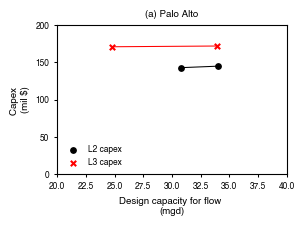

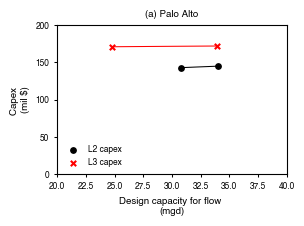

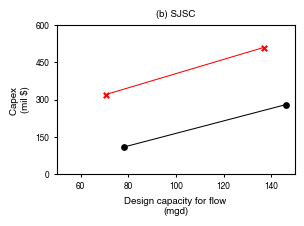

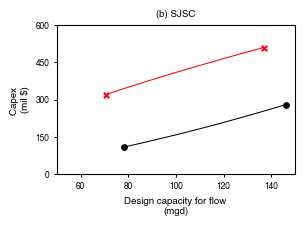

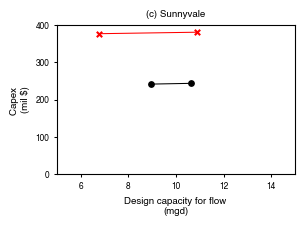

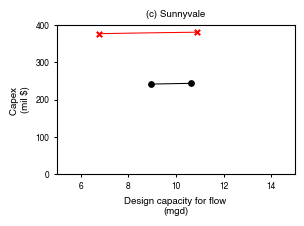

In [ ]:
for i,WWTP in enumerate(LSB['Abbreviation']):
    plot_capex_WWTP_flow(WWTP, i, eq_type= 'linear')
    plot_capex_WWTP_flow(WWTP, i, eq_type= 'power')

Linear fit:
WWTP: Palo Alto
        Design capacity for L2 between: 2628 lb/day and 2902 lb/day
        Design capacity for L3 between: 3974 lb/day and 5445 lb/day
Power fit:
WWTP: Palo Alto
        Design capacity for L2 between: 2628 lb/day and 2902 lb/day
        Design capacity for L3 between: 3974 lb/day and 5445 lb/day
Power law L2: C = 47.5 * X^0.140
Power law L3: C = 147 * X^0.0185
Linear fit:
WWTP: SJSC
        Design capacity for L2 between: 1453 lb/day and 2717 lb/day
        Design capacity for L3 between: 6575 lb/day and 12822 lb/day
Power fit:
WWTP: SJSC
        Design capacity for L2 between: 1453 lb/day and 2717 lb/day
        Design capacity for L3 between: 6575 lb/day and 12822 lb/day
Power law L2: C = 0.00209 * X^1.49
Power law L3: C = 0.693 * X^0.698
Linear fit:
WWTP: Sunnyvale
        Design capacity for L2 between: 544 lb/day and 645 lb/day
        Design capacity for L3 between: 918 lb/day and 1480 lb/day
Power fit:
WWTP: Sunnyvale
        Design capacity for L2 

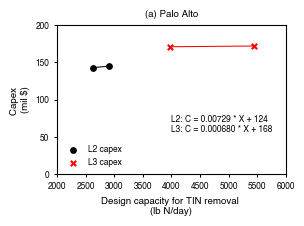

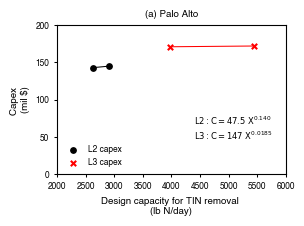

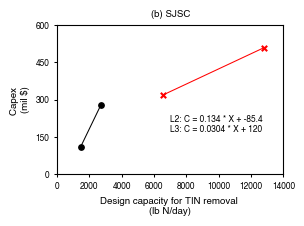

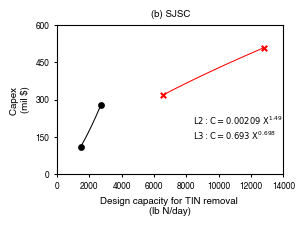

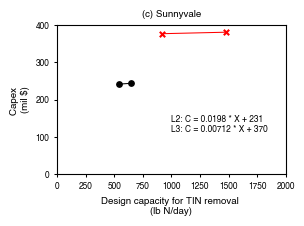

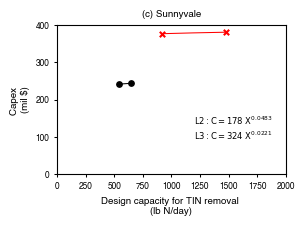

In [ ]:
for i,WWTP in enumerate(LSB['Abbreviation']):
    name = '/S11'
    print('Linear fit:')
    plot_capex_WWTP(WWTP, i, eq_type= 'linear')
    name = '/S12'
    print('Power fit:')
    plot_capex_WWTP(WWTP, i, eq_type= 'power')

# Plot Opex Best Fit Line

In [ ]:
# import path as dataframe
import pandas as pd
import numpy as np

name = '/S10'

path = '../Input_Data/Sidestream_opex_BACWA.csv'
df = pd.read_csv(path)

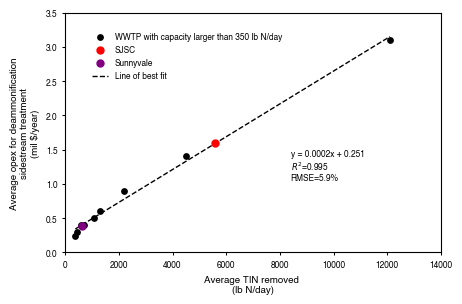

In [ ]:
colors = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'L2upg3': '#EB5E28'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2

abb = {'SJSC': 'San Jose-Santa Clara Regional Wastewater Facility ', 'Sunnyvale': 'City of Sunnyvale'}

# Select WWTPs with sidestream larger than 350 lb N/day
TN = df[df['TN_removal'] > 350].TN_removal 
opex = df[df['TN_removal'] > 350].Opex

# create figure
fig, ax = plt.subplots(1,1, figsize=(120/25.4, 80/25.4))

# plot data points
plt.scatter(TN, opex, color='black', label='WWTP with capacity larger than 350 lb N/day', marker='o', s=15, zorder=2.5)
plt.scatter(df[df.WWTP == abb['SJSC']].TN_removal, df[df.WWTP == abb['SJSC']].Opex, color='red', label='SJSC', marker='o', s=25, zorder=2.5)
plt.scatter(df[df.WWTP == abb['Sunnyvale']].TN_removal, df[df.WWTP == abb['Sunnyvale']].Opex, color='purple', label='Sunnyvale', marker='o', s=25, zorder=2.5)


# find best fit linear line 
# create new list that contains both opex_avg_L2 and opex_avg_L3
        
z = np.polyfit(TN, opex, 1)
p = np.poly1d(z)
plt.plot(TN, p(TN), color='black', linestyle='--', linewidth=1, label='Line of best fit')

#calculate R2
r2 = np.corrcoef(opex, p(TN))[0, 1]**2

#calculate RMSE
rmse = np.sqrt(np.mean((p(TN) - opex)**2))*100



ax.set_xlabel('Average TIN removed \n(lb N/day)', **hfont)
ax.set_ylabel('Average opex for deammonification\nsidestream treatment\n(mil $/year)', **hfont)
min_x = 0
max_x = 14000
ax.set_xlim(min_x, max_x)
ax.set_xticks(np.arange(0, max_x+1, 2000))

max_y = 3.5
ax.set_ylim(0, max_y)
ax.set_yticks(np.arange(0, max_y+0.1, 0.5))


x_scale = 1.2
y_scale = 0.3

# add equation for best fit line
text1 = 'y = ' + str(round(z[0], 4)) + 'x + ' + str(round(z[1], 3))
text2 = '$R^{2}$=%.3f'%r2
text3 = 'RMSE=%.1f'%rmse + '%'

plt.text((min_x + max_x)/2 * x_scale, max_y * y_scale, text1 + '\n' + text2 + '\n' + text3, fontsize=leg_size, color='black', fontfamily='Helvetica')



ax.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
ax.tick_params(axis="both", width=line_wid, length=bord_wid)

ax.legend(loc='upper left', fontsize=10, frameon=False, bbox_to_anchor=(0.05, 0.95), prop={'family':'Helvetica', 'size':leg_size})
fig.tight_layout()

fig.savefig(file + '/SI' + name + ".svg", format="svg", dpi=300)